# 06 · Selección del mejor modelo y prueba final en test

> **Flujo del proyecto** (diagrama del profesor)
> `01 Limpieza` → `02 Exploración` → `03 Creación de variables` → `04 Preparación (split temporal + folds)` →
> `05a Logística` · `05b Random Forest` · `05c XGBoost` · `05d Red neuronal` (cada uno: selección de variables → hiperparámetros) →
> `06 Selección del mejor modelo y prueba final en test`


    1. **Comparación en el K-Fold temporal** (nunca en test): PR-AUC de validación para elegir; brecha de ROC-AUC train–validación para diagnosticar sobreajuste.
    2. **Mejor modelo clásico** (Módulo 3) = mayor PR-AUC de validación; si dos quedan a menos de 0.005, gana el más simple
       (Logística → Random Forest → XGBoost).
    3. **Prueba final:** se abre el test **una sola vez** para el mejor modelo clásico y la red neuronal (comparación que pide el Módulo 4).
    4. Traducción a negocio.

In [1]:
import sys, json, time, warnings
from pathlib import Path

RAIZ = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(RAIZ))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from src import config, viz
viz.aplicar_estilo()
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 200)

import joblib
from sklearn.metrics import precision_recall_curve, ConfusionMatrixDisplay
from src import evaluacion as E, red_neuronal as R

In [2]:
TODOS = config.MODELOS_CLASICOS + [config.NOMBRE_RED]
carpeta = {n: config.MODELOS / config.CLAVES_MODELO[n] for n in TODOS}
resumen = {n: json.loads((carpeta[n] / "resumen.json").read_text()) for n in TODOS}
cv = {n: pd.read_csv(carpeta[n] / "cv_folds.csv") for n in TODOS}
oof = {n: pd.read_parquet(carpeta[n] / "oof.parquet") for n in TODOS}

comp = pd.DataFrame({n: {
    "Variables": resumen[n]["n_variables"],
    "PR-AUC val (prom)": cv[n]["PR-AUC val"].mean(), "PR-AUC val (desv)": cv[n]["PR-AUC val"].std(),
    "ROC-AUC val (prom)": cv[n]["ROC-AUC val"].mean(),
    "ROC-AUC train (prom)": cv[n]["ROC-AUC train"].mean(),
    "Brecha ROC train-val": cv[n]["ROC-AUC train"].mean() - cv[n]["ROC-AUC val"].mean(),
    "F1 fuera de fold": E.metricas(oof[n]["y"], oof[n]["prob"], resumen[n]["umbral"])["F1"],
    "Umbral": resumen[n]["umbral"],
} for n in TODOS}).T.astype(float)
azar_cv = oof[TODOS[0]]["y"].mean()
comp["PR-AUC val / azar"] = comp["PR-AUC val (prom)"] / azar_cv
display(comp.sort_values("PR-AUC val (prom)", ascending=False).round(4))
print(f"Azar en validación (tasa de tardíos fuera de fold): {azar_cv:.4f}")

,Variables,PR-AUC val (prom),PR-AUC val (desv),ROC-AUC val (prom),ROC-AUC train (prom),Brecha ROC train-val,F1 fuera de fold,Umbral,PR-AUC val / azar
Red Neuronal,35.0,0.1895,0.1317,0.6755,0.7569,0.0814,0.2265,0.6109,2.2827
Random Forest,105.0,0.1578,0.0907,0.6596,0.8667,0.2071,0.2701,0.4094,1.9006
XGBoost,35.0,0.1574,0.0885,0.6437,0.8414,0.1978,0.2311,0.1510,1.8966
Regresión Logística,65.0,0.1532,0.0998,0.6499,0.7258,0.0759,0.2265,0.5993,1.8460


Azar en validación (tasa de tardíos fuera de fold): 0.0830


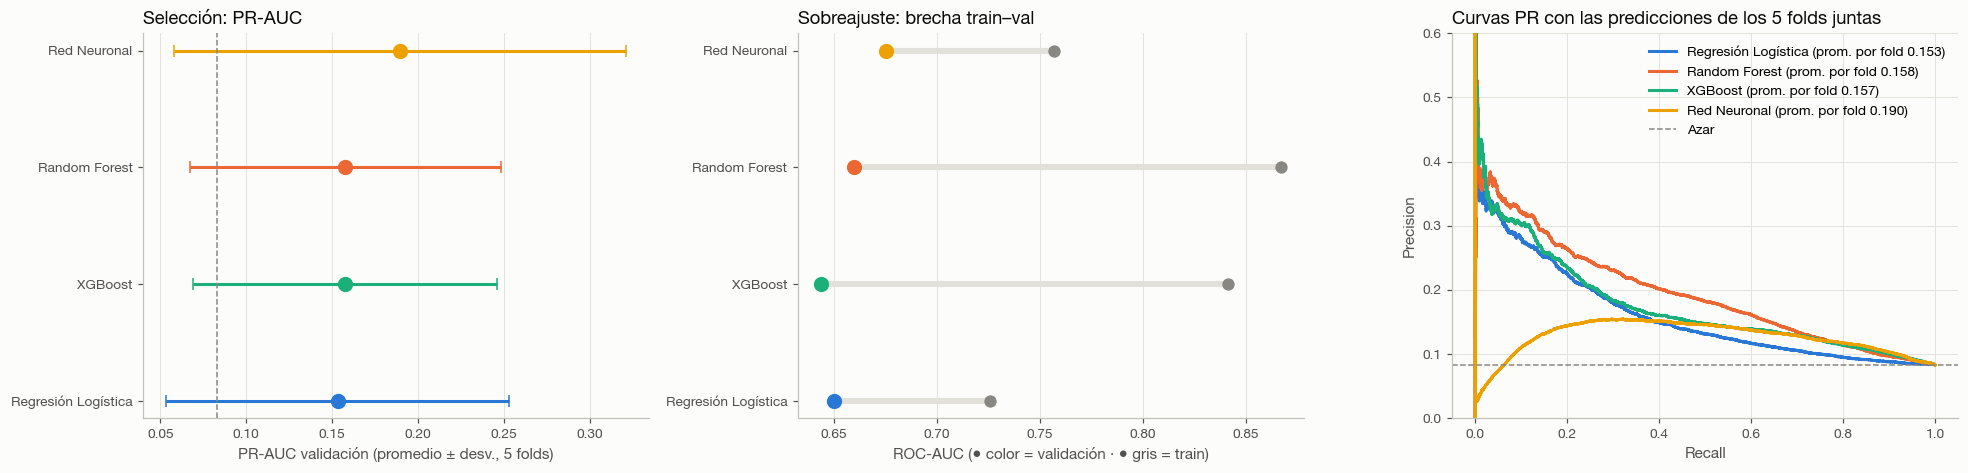

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.4))
orden = comp.sort_values("PR-AUC val (prom)").index
for i, n in enumerate(orden):
    axes[0].errorbar(comp.loc[n, "PR-AUC val (prom)"], i, xerr=comp.loc[n, "PR-AUC val (desv)"], fmt="o",
                     color=viz.COLOR_MODELO[n], ms=9, capsize=4)
    axes[1].plot([comp.loc[n, "ROC-AUC val (prom)"], comp.loc[n, "ROC-AUC train (prom)"]], [i, i], color=viz.GRID, linewidth=4, zorder=1)
    axes[1].scatter(comp.loc[n, "ROC-AUC train (prom)"], i, color=viz.NEUTRO, s=50, zorder=2)
    axes[1].scatter(comp.loc[n, "ROC-AUC val (prom)"], i, color=viz.COLOR_MODELO[n], s=80, zorder=3)
axes[0].axvline(azar_cv, color=viz.NEUTRO, linestyle="--", linewidth=1)
axes[0].set_xlabel("PR-AUC validación (promedio ± desv., 5 folds)"); axes[0].set_title("Selección: PR-AUC")
axes[1].set_xlabel("ROC-AUC (● color = validación · ● gris = train)"); axes[1].set_title("Sobreajuste: brecha train–val")
for ax in axes[:2]:
    ax.set_yticks(range(len(orden)), orden); ax.grid(axis="y", visible=False)
for n in TODOS:
    p, r, _ = precision_recall_curve(oof[n]["y"], oof[n]["prob"])
    axes[2].plot(r, p, color=viz.COLOR_MODELO[n], label=f"{n} (prom. por fold {comp.loc[n, 'PR-AUC val (prom)']:.3f})")
axes[2].axhline(azar_cv, color=viz.NEUTRO, linestyle="--", linewidth=1, label="Azar")
axes[2].set_ylim(0, 0.6); axes[2].set_xlabel("Recall"); axes[2].set_ylabel("Precision")
axes[2].set_title("Curvas PR con las predicciones de los 5 folds juntas"); axes[2].legend()
plt.tight_layout()
viz.guardar(fig, "comparacion_cv"); plt.show()

**Cómo leer la curva de la derecha:** junta las predicciones de los 5 folds, y cada fold es un modelo distinto con su propia escala
de probabilidades. Un modelo puede ordenar muy bien dentro de cada fold (PR-AUC promedio alto) y aun así verse peor al juntar folds,
como la red neuronal. Por eso **la selección usa el PR-AUC promedio por fold**, y por eso un umbral fijo de probabilidad elegido
con las predicciones juntas puede no transferirse bien al futuro (ver la prueba final).

### Selección (sólo con el CV)

In [4]:
pr_cv = {n: comp.loc[n, "PR-AUC val (prom)"] for n in TODOS}
mejor_clasico = E.mejor_modelo({n: pr_cv[n] for n in config.MODELOS_CLASICOS}, config.MODELOS_CLASICOS)
ganador = E.mejor_modelo(pr_cv, config.MODELOS_CLASICOS + [config.NOMBRE_RED])   # la red es la más compleja
print("PR-AUC CV:", {n: round(v, 4) for n, v in pr_cv.items()})
print("Mejor modelo clásico (Módulo 3):", mejor_clasico)
print("Modelo recomendado según el CV (empates -> el más simple):", ganador)
A_TEST = [mejor_clasico, config.NOMBRE_RED]

PR-AUC CV: {'Regresión Logística': 0.1532, 'Random Forest': 0.1578, 'XGBoost': 0.1574, 'Red Neuronal': 0.1895}
Mejor modelo clásico (Módulo 3): Regresión Logística
Modelo recomendado según el CV (empates -> el más simple): Red Neuronal


## Prueba final en test (se abre una sola vez)
Cada modelo se re-entrenó con todo el train (05x) y usa el umbral que eligió con sus predicciones fuera de fold.

In [5]:
X_test = pd.read_parquet(config.DATOS_PROCESSED / "X_test.parquet")
meta_test = pd.read_parquet(config.DATOS_PROCESSED / "meta_test.parquet")
y_test = meta_test["delivery_late"]

modelos = {}
for n in A_TEST:
    if n == config.NOMBRE_RED:
        modelos[n] = R.RedCargada(carpeta[n])
    else:
        modelos[n] = joblib.load(carpeta[n] / "modelo.joblib")
variables = {n: json.loads((carpeta[n] / "best_features.json").read_text()) for n in A_TEST}
prob_test = {n: (modelos[n].predict_proba(X_test) if n == config.NOMBRE_RED
                 else modelos[n].predict_proba(X_test[variables[n]]))[:, 1] for n in A_TEST}

azar_test = y_test.mean()
res_test = pd.DataFrame({n: {**E.metricas(y_test, prob_test[n], resumen[n]["umbral"]),
                             "Umbral": resumen[n]["umbral"], "PR-AUC CV": pr_cv[n]} for n in A_TEST}).T.astype(float)
res_test["PR-AUC / azar"] = res_test["PR-AUC"] / azar_test
display(res_test[["PR-AUC CV", "PR-AUC", "PR-AUC / azar", "ROC-AUC", "Precision", "Recall", "F1", "Accuracy", "Umbral"]].round(4))
print(f"Test: {len(y_test):,} pedidos, {y_test.sum():,} tardíos ({azar_test:.2%}) -> PR-AUC del azar = {azar_test:.4f}")

,PR-AUC CV,PR-AUC,PR-AUC / azar,ROC-AUC,Precision,Recall,F1,Accuracy,Umbral
Regresión Logística,0.1532,0.0981,2.2299,0.7165,0.0679,0.8646,0.1259,0.4719,0.5993
Red Neuronal,0.1895,0.0951,2.1612,0.7291,0.0676,0.8709,0.1255,0.4664,0.6109


Test: 25,350 pedidos, 1,115 tardíos (4.40%) -> PR-AUC del azar = 0.0440


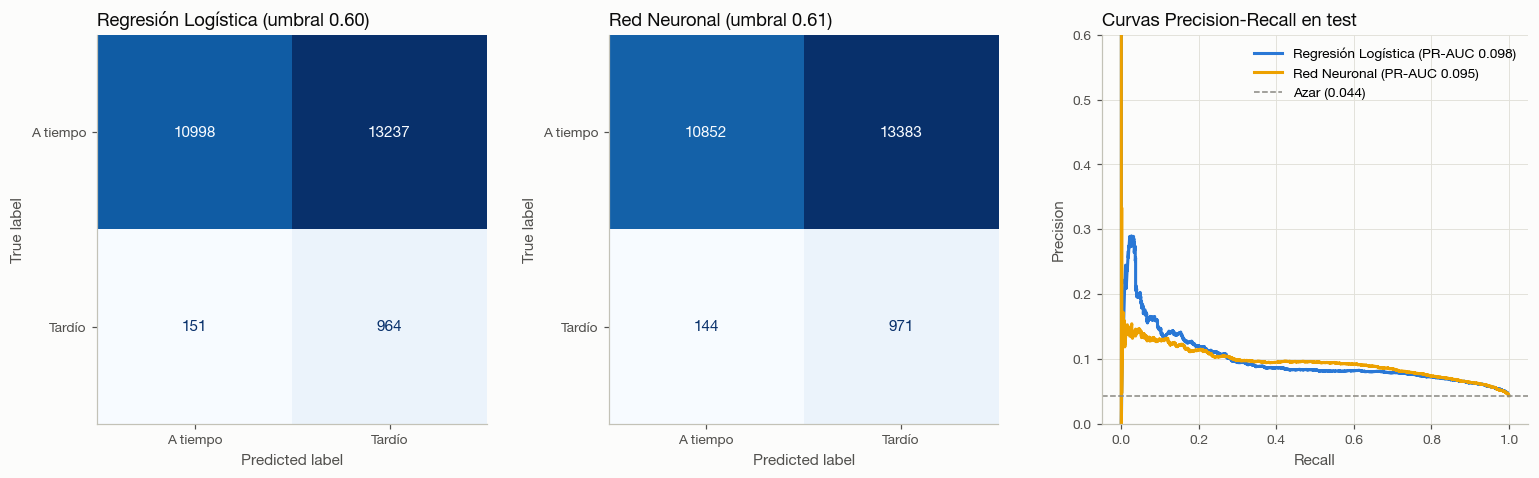

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
for ax, n in zip(axes[:2], A_TEST):
    pred = (prob_test[n] >= resumen[n]["umbral"]).astype(int)
    ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["A tiempo", "Tardío"], cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(f"{n} (umbral {resumen[n]['umbral']:.2f})"); ax.grid(False)
for n in A_TEST:
    p, r, _ = precision_recall_curve(y_test, prob_test[n])
    axes[2].plot(r, p, color=viz.COLOR_MODELO[n], label=f"{n} (PR-AUC {res_test.loc[n, 'PR-AUC']:.3f})")
axes[2].axhline(azar_test, color=viz.NEUTRO, linestyle="--", linewidth=1, label=f"Azar ({azar_test:.3f})")
axes[2].set_ylim(0, 0.6); axes[2].set_xlabel("Recall"); axes[2].set_ylabel("Precision")
axes[2].set_title("Curvas Precision-Recall en test"); axes[2].legend()
viz.guardar(fig, "test_final"); plt.show()

**Nota sobre el umbral.** El umbral se eligió en validación (F1 máximo), cuando la tasa de retraso era mayor. En el test la tasa bajó
y las escalas de probabilidad cambian, así que un umbral fijo marca demasiados pedidos (recall alto, precisión baja). La métrica que
no depende del umbral (PR-AUC) y la **operación por capacidad** (revisar el *k* % de pedidos más riesgosos) son más robustas a la deriva.

## Traducción a negocio
El modelo entrega una **probabilidad de retraso** por pedido. Si el equipo de operaciones revisa sólo el *k* % de pedidos
más riesgosos, ¿qué porcentaje de los retrasos captura?

Regresión Logística


,% pedidos revisados,% tardíos capturados,Precision,Lift
0,5.0,15.605,0.137,3.120
1,10.0,24.933,0.110,2.493
2,20.0,39.372,0.087,1.969
3,30.0,56.054,0.082,1.868


Red Neuronal


,% pedidos revisados,% tardíos capturados,Precision,Lift
0,5.0,13.991,0.123,2.797
1,10.0,23.767,0.105,2.377
2,20.0,43.498,0.096,2.175
3,30.0,62.063,0.091,2.069


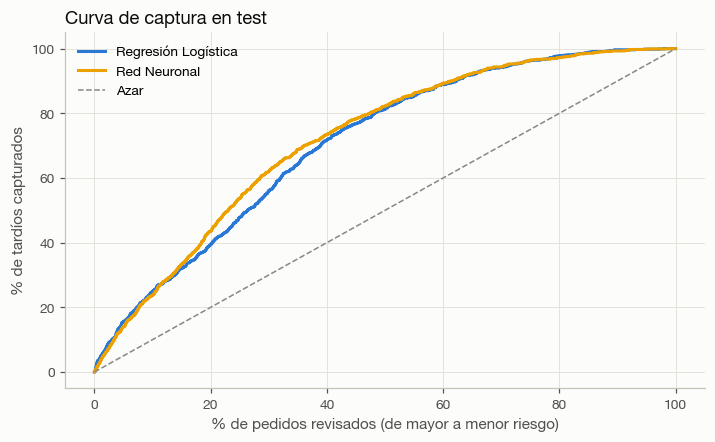

In [7]:
captura = {n: E.captura_top_k(y_test, prob_test[n]) for n in A_TEST}
for n in A_TEST:
    print(n); display(captura[n].round(3))

fig, ax = plt.subplots(figsize=(7.5, 4.2))
fr = np.linspace(0, 1, 101)
for n in A_TEST:
    y_ord = y_test.to_numpy()[np.argsort(-prob_test[n])]
    curva = np.concatenate([[0], np.cumsum(y_ord)]) / y_ord.sum()
    ax.plot(np.linspace(0, 100, len(curva)), curva * 100, color=viz.COLOR_MODELO[n], label=n)
ax.plot([0, 100], [0, 100], color=viz.NEUTRO, linestyle="--", linewidth=1, label="Azar")
ax.set_xlabel("% de pedidos revisados (de mayor a menor riesgo)"); ax.set_ylabel("% de tardíos capturados")
ax.set_title("Curva de captura en test"); ax.legend()
viz.guardar(fig, "captura_test"); plt.show()

### Variables más importantes del mejor modelo clásico

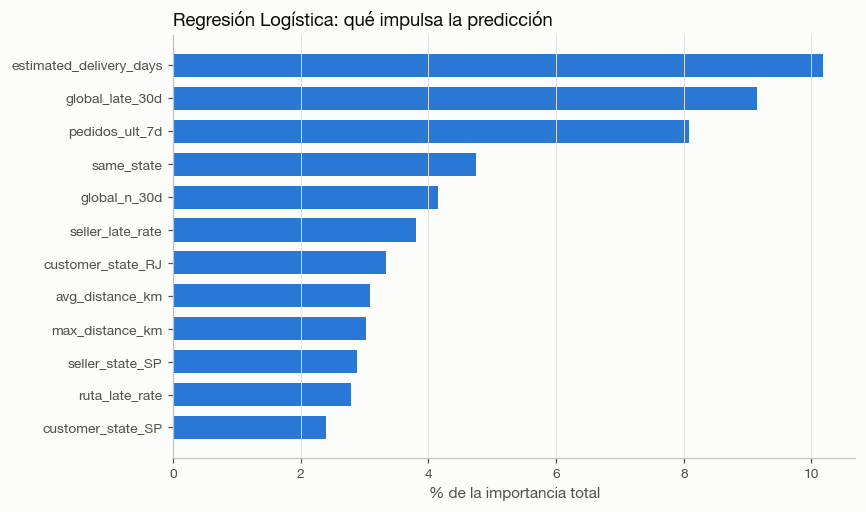

In [8]:
m = modelos[mejor_clasico].named_steps["modelo"]
if hasattr(m, "feature_importances_"):
    imp = pd.Series(m.feature_importances_, index=variables[mejor_clasico])
else:
    imp = pd.Series(np.abs(m.coef_[0]), index=variables[mejor_clasico])
imp = (imp / imp.sum()).sort_values(ascending=False)
top = imp.head(12).sort_values()
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top.index, top.values * 100, color=viz.COLOR_MODELO[mejor_clasico], height=0.7); ax.grid(axis="y", visible=False)
ax.set_xlabel("% de la importancia total"); ax.set_title(f"{mejor_clasico}: qué impulsa la predicción")
viz.guardar(fig, "importancia_final"); plt.show()

### Lectura de resultados y limitaciones
- **PR-AUC / azar** dice cuántas veces mejor que adivinar ordena el modelo los pedidos por riesgo.
- El umbral se puede mover según el costo: avisar al cliente es barato (umbral bajo, más recall); intervenir la logística es caro (umbral alto, más precisión).
- La tasa de retraso cambia mucho entre periodos (el test tiene menos retrasos que el train), no hay datos de transportista ni de clima,
  y la fecha estimada de Olist ya absorbe parte del riesgo.
- La métrica del CV es optimista (los mismos folds eligieron variables, hiperparámetros y umbral); por eso el test aparte.

In [9]:
def curva_pr(y, p, n=60):
    pr, rc, _ = precision_recall_curve(y, p)
    idx = np.unique(np.linspace(0, len(pr) - 1, 400).astype(int))
    return {"recall": rc[idx].round(4).tolist(), "precision": pr[idx].round(4).tolist()}

def curva_captura(y, p):
    y_ord = np.asarray(y)[np.argsort(-np.asarray(p))]
    c = np.concatenate([[0], np.cumsum(y_ord)]) / y_ord.sum()
    idx = np.linspace(0, len(c) - 1, 101).astype(int)
    return (c[idx] * 100).round(2).tolist()

resultados = {
    "comparacion_cv": json.loads(comp.reset_index(names="Modelo").to_json(orient="records")),
    "cv_por_fold": {n: json.loads(cv[n].to_json(orient="records")) for n in TODOS},
    "azar_cv": float(azar_cv), "mejor_clasico": mejor_clasico, "ganador_cv": ganador,
    "test": json.loads(res_test.reset_index(names="Modelo").to_json(orient="records")),
    "azar_test": float(azar_test), "n_test": int(len(y_test)), "tardios_test": int(y_test.sum()),
    "captura": {n: json.loads(captura[n].to_json(orient="records")) for n in A_TEST},
    "curva_captura": {n: curva_captura(y_test, prob_test[n]) for n in A_TEST},
    "curva_pr_test": {n: curva_pr(y_test, prob_test[n]) for n in A_TEST},
    "curva_pr_oof": {n: curva_pr(oof[n]["y"], oof[n]["prob"]) for n in TODOS},
    "importancia": {k: float(v) for k, v in imp.head(12).items()},
    "resumen_modelos": resumen,
}
for n in A_TEST:
    pred = (prob_test[n] >= resumen[n]["umbral"]).astype(int)
    resultados.setdefault("confusion", {})[n] = {
        "tn": int(((pred == 0) & (y_test == 0)).sum()), "fp": int(((pred == 1) & (y_test == 0)).sum()),
        "fn": int(((pred == 0) & (y_test == 1)).sum()), "tp": int(((pred == 1) & (y_test == 1)).sum())}
(config.METRICAS / "resultados.json").write_text(json.dumps(resultados, indent=2, ensure_ascii=False))
print("Resultados exportados a", config.METRICAS / "resultados.json")

Resultados exportados a /Users/fabiolajrz/Documents/proyecto_final_equipo_3/reportes/metricas/resultados.json


## Conclusión

In [10]:
nn, mc = config.NOMBRE_RED, mejor_clasico
lineas = [
    f"- **Validación (CV):** mejor modelo clásico = **{mc}** (PR-AUC {pr_cv[mc]:.3f}); red neuronal PR-AUC {pr_cv[nn]:.3f}. "
    f"Modelo recomendado por la regla definida de antemano: **{ganador}**.",
    f"- **Test (una sola vez):** {mc} PR-AUC {res_test.loc[mc, 'PR-AUC']:.3f} ({res_test.loc[mc, 'PR-AUC / azar']:.1f}× el azar) · "
    f"red PR-AUC {res_test.loc[nn, 'PR-AUC']:.3f} ({res_test.loc[nn, 'PR-AUC / azar']:.1f}× el azar).",
]
dif = res_test.loc[nn, "PR-AUC"] - res_test.loc[mc, "PR-AUC"]
if abs(dif) < 0.01:
    lineas.append(f"- En test ambos modelos son **prácticamente equivalentes** (diferencia de PR-AUC {dif:+.3f}): la ventaja de la red "
                  f"en validación no se sostuvo en el futuro. Para un piloto conviene {mc} (más simple y explicable), con la red como modelo retador.")
lineas.append(f"- **Operación por capacidad:** revisando el 20 % de pedidos más riesgosos, {mc} anticipa el "
              f"{captura[mc].loc[captura[mc]['% pedidos revisados'] == 20, '% tardíos capturados'].iloc[0]:.0f} % de los retrasos.")
display(Markdown("\n".join(lineas)))

- **Validación (CV):** mejor modelo clásico = **Regresión Logística** (PR-AUC 0.153); red neuronal PR-AUC 0.190. Modelo recomendado por la regla definida de antemano: **Red Neuronal**.
- **Test (una sola vez):** Regresión Logística PR-AUC 0.098 (2.2× el azar) · red PR-AUC 0.095 (2.2× el azar).
- En test ambos modelos son **prácticamente equivalentes** (diferencia de PR-AUC -0.003): la ventaja de la red en validación no se sostuvo en el futuro. Para un piloto conviene Regresión Logística (más simple y explicable), con la red como modelo retador.
- **Operación por capacidad:** revisando el 20 % de pedidos más riesgosos, Regresión Logística anticipa el 39 % de los retrasos.